# RAGAS reproducibility
ICC (statsmodels mixed model), repeatability and replicate plots.

In [5]:
import itertools, warnings
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore")
rng = np.random.default_rng(42)

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "RAGAS_Reproducibility" / "Results"

FILE = DATA_DIR / "50_articles_combined_ragas_scores_gpt-5-mini_2026.csv"   # .xlsx or .csv
N_REPS = 5
N_BOOT = 500             # lower (e.g. 50) for a quick run
INPUTS, METRICS = ["Abstract", "FullText"], ["Faithfulness", "Summarization"]

In [6]:
def rep_cols(inp, met):
    return [f"{inp}_RAGAS_{met}_Rep_{i}" for i in range(1, N_REPS + 1)]

if FILE.suffix.lower() == ".csv":
    df = pd.read_csv(FILE)
else:
    df = pd.read_excel(FILE)
df.shape

(50, 60)

## ICC
One-way random-effects model `score ~ 1 + (1 | document)`: ICC(1,1) for a single run, ICC(1,k) for the mean of k runs. CIs via cluster bootstrap over documents.

In [25]:
def to_long(wide):
    long = wide.reset_index(drop=True).copy()
    long.columns = range(wide.shape[1])
    long["doc"] = np.arange(len(long))
    return long.melt(id_vars="doc", value_name="score").drop(columns="variable")

def icc_mixed(wide):
    long = to_long(wide)
    m = smf.mixedlm("score ~ 1", long, groups=long["doc"]).fit(reml=True)
    var_doc, var_res = float(m.cov_re.iloc[0, 0]), float(m.scale)
    k = wide.shape[1]
    return var_doc / (var_doc + var_res), var_doc / (var_doc + var_res / k), var_res

def bootstrap_ci(wide):
    vals, n = [], len(wide)
    for _ in range(N_BOOT):
        try:
            vals.append(icc_mixed(wide.iloc[rng.integers(0, n, n)])[:2])
        except Exception:
            pass
    return np.percentile(np.array(vals), [2.5, 97.5], axis=0)

In [26]:
rows = []
for inp, met in itertools.product(INPUTS, METRICS):
    wide = df[rep_cols(inp, met)].dropna()
    icc1, icck, var_res = icc_mixed(wide)
    lo, hi = bootstrap_ci(wide)
    sw_doc = wide.std(axis=1, ddof=1)
    sw = np.sqrt(var_res)
    rows.append({
        "Metric": met, "Input": inp, "n_docs": len(wide),
        "ICC(1,1)": icc1, "ICC(1,1) lo": lo[0], "ICC(1,1) hi": hi[0],
        "ICC(1,k)": icck, "ICC(1,k) lo": lo[1], "ICC(1,k) hi": hi[1],
        "Median within-doc SD": sw_doc.median(),
        "Pooled Sw - Weighted Avg of Within-Article Standard Deviation (Sw)": sw,
        "Repeatability coef": 2.77 * sw,
        "Mean pairwise Spearman": np.mean([wide[a].corr(wide[b], method="spearman")
                                           for a, b in itertools.combinations(wide.columns, 2)]),
        "Proportion at RAGAS score maximum (1)": (wide.values >= 0.999).mean(),
    })
res = pd.DataFrame(rows)
res.to_csv("reproducibility_table.csv", index=False)
res.round(3)

,Metric,Input,n_docs,"ICC(1,1)","ICC(1,1) lo","ICC(1,1) hi","ICC(1,k)","ICC(1,k) lo","ICC(1,k) hi",Median within-doc SD,Pooled Sw - Weighted Avg of Within-Article Standard Deviation (Sw),Repeatability coef,Mean pairwise Spearman,Proportion at RAGAS score maximum (1)
0,Faithfulness,Abstract,50,0.640,0.459,0.762,0.899,0.809,0.941,0.032,0.043,0.120,0.625,0.204
1,Summarization,Abstract,50,0.552,0.369,0.711,0.860,0.745,0.925,0.053,0.082,0.228,0.574,0.000
2,Faithfulness,FullText,50,0.456,0.225,0.623,0.807,0.592,0.892,0.027,0.032,0.089,0.458,0.588
3,Summarization,FullText,50,0.572,0.402,0.695,0.870,0.770,0.919,0.019,0.024,0.065,0.560,0.000


## Main figure: caterpillar plots

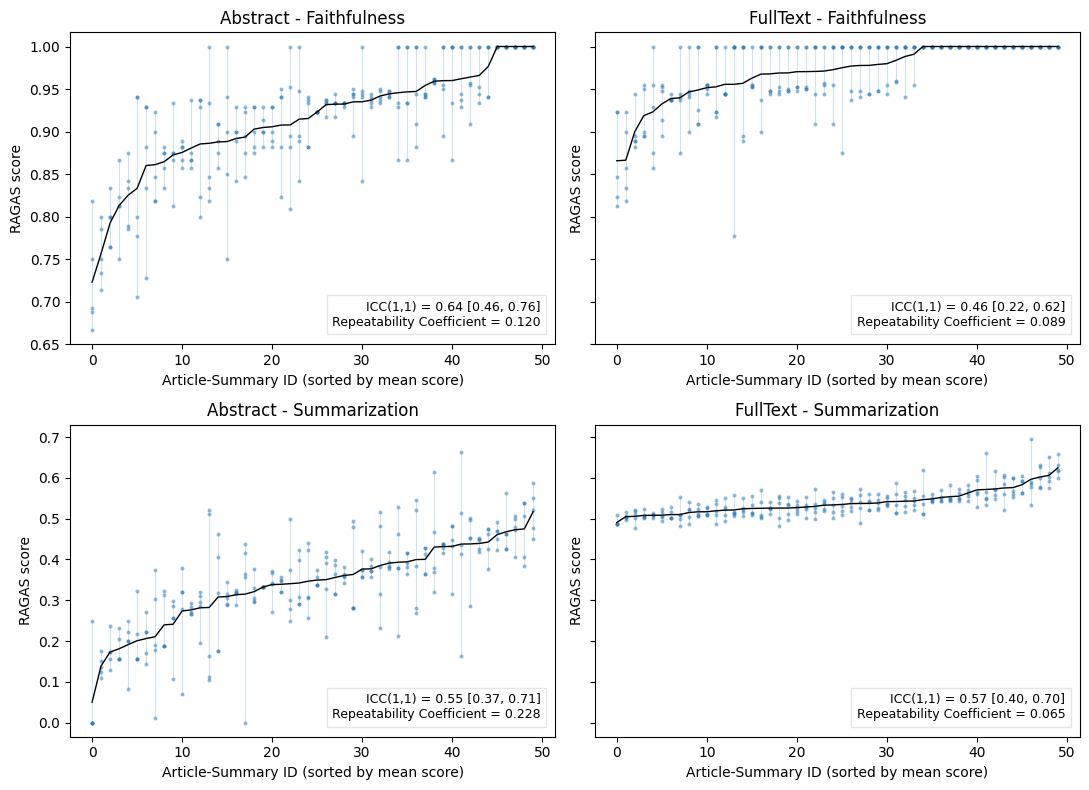

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey="row")
for ax, (met, inp) in zip(axes.flat, itertools.product(METRICS, INPUTS)):
    wide = df[rep_cols(inp, met)].dropna()
    w = wide.loc[wide.mean(axis=1).sort_values().index].values
    x = np.arange(len(w))
    for j in range(w.shape[1]):
        ax.scatter(x, w[:, j], s=8, alpha=.5, color="tab:blue", lw=0)
    ax.plot(x, w.mean(axis=1), color="k", lw=1)
    ax.vlines(x, w.min(axis=1), w.max(axis=1), color="tab:blue", alpha=.2, lw=.8)
    r = res[(res.Metric == met) & (res.Input == inp)].iloc[0]
    ax.set_title(f"{inp} - {met}")
    ax.text(.97, .05, f"ICC(1,1) = {r['ICC(1,1)']:.2f} [{r['ICC(1,1) lo']:.2f}, {r['ICC(1,1) hi']:.2f}]\n"
                      f"Repeatability Coefficient = {r['Repeatability coef']:.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9, bbox=dict(fc="white", ec="0.9"))
    ax.set_xlabel("Article-Summary ID (sorted by mean score)"); ax.set_ylabel("RAGAS score")
fig.tight_layout()
fig.savefig("fig_caterpillar.png", dpi=300); fig.savefig("fig_caterpillar.pdf")



## Supplementary: Bland-Altman (each rep vs mean of the other reps)

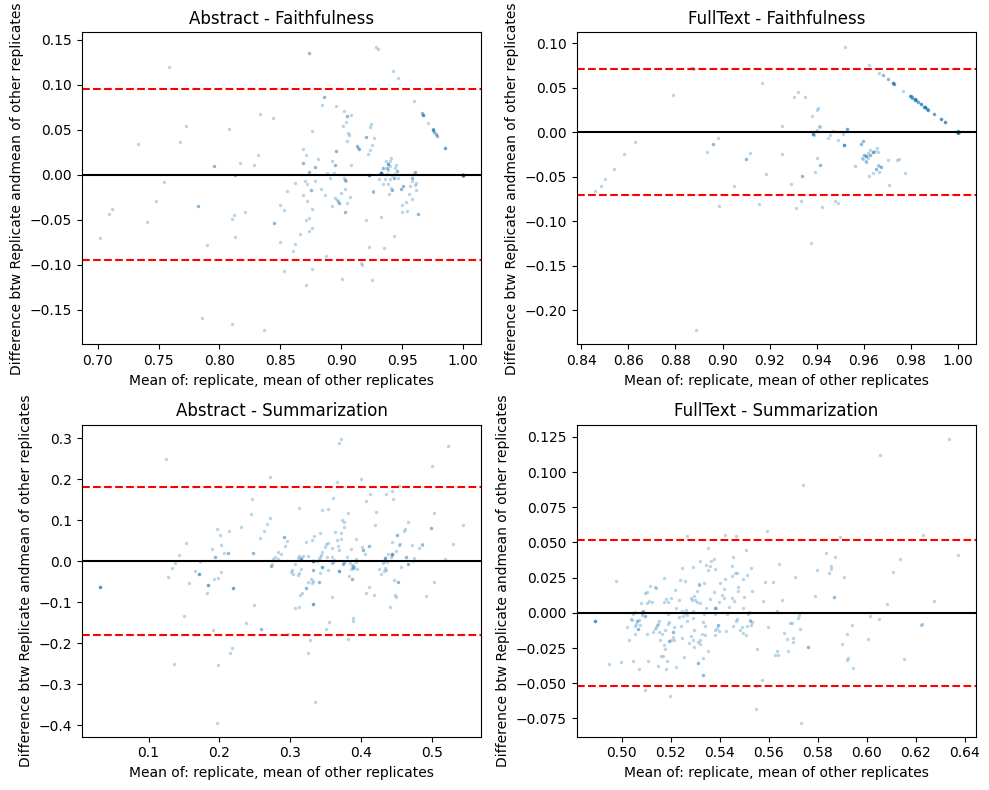

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (met, inp) in zip(axes.flat, itertools.product(METRICS, INPUTS)):
    w = df[rep_cols(inp, met)].dropna().values
    means, diffs = [], []
    for j in range(w.shape[1]):
        others = np.delete(w, j, axis=1).mean(axis=1)
        means.append((w[:, j] + others) / 2); diffs.append(w[:, j] - others)
    means, diffs = np.concatenate(means), np.concatenate(diffs)
    bias, sd = diffs.mean(), diffs.std(ddof=1)
    ax.scatter(means, diffs, s=6, alpha=.3, lw=0)
    ax.axhline(bias, color="k")
    for s in (-1.96, 1.96):
        ax.axhline(bias + s * sd, color="r", ls="--")
    ax.set_title(f"{inp} - {met}")
    ax.set_xlabel("Mean of: replicate, mean of other replicates"); ax.set_ylabel("Difference btw Replicate andmean of other replicates")
fig.tight_layout(); fig.savefig("figS_bland_altman.png", dpi=300)

## Supplementary: rep-vs-rep scatter and SD vs mean

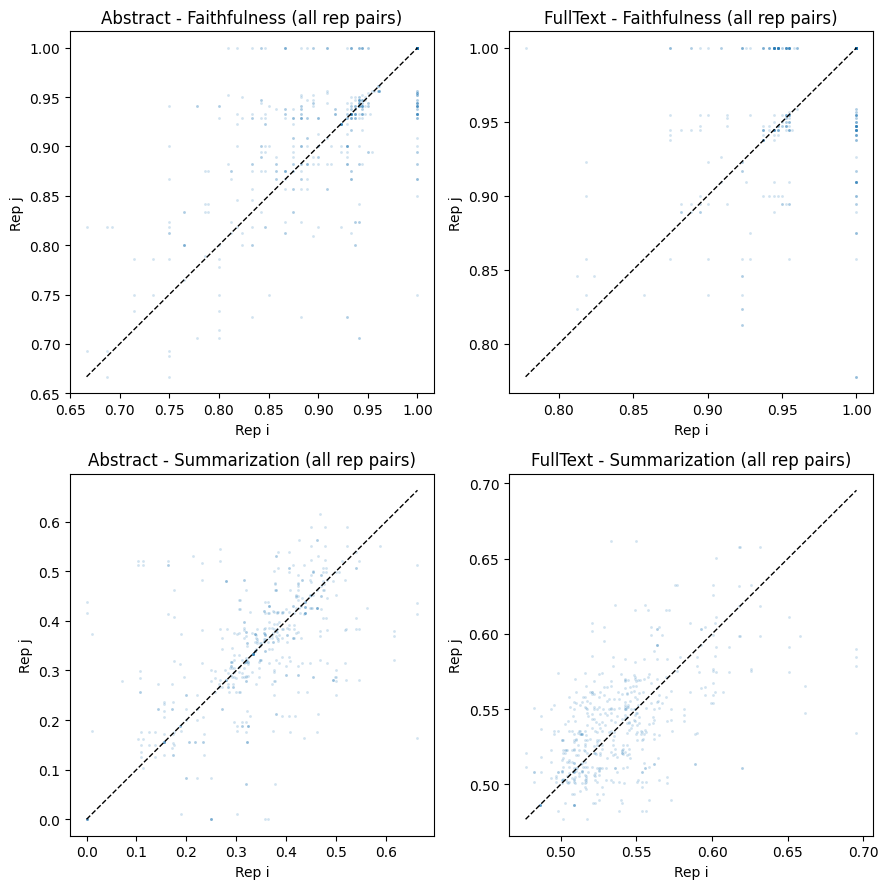

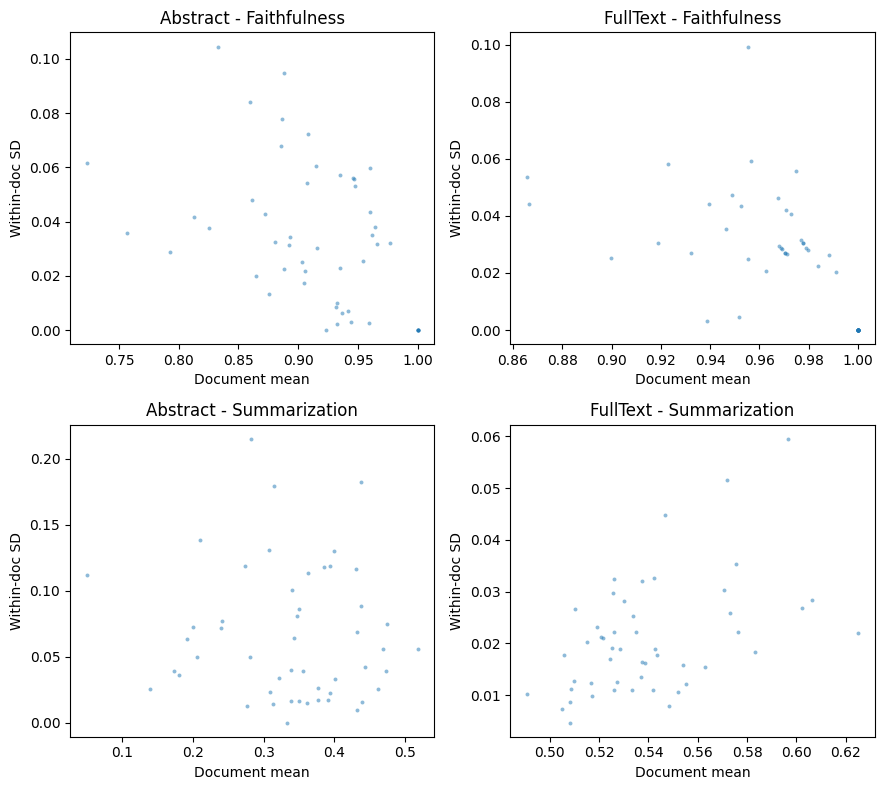

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, (met, inp) in zip(axes.flat, itertools.product(METRICS, INPUTS)):
    w = df[rep_cols(inp, met)].dropna()
    for a, b in itertools.combinations(w.columns, 2):
        ax.scatter(w[a], w[b], s=4, alpha=.2, lw=0, color="tab:blue")
    lim = [w.values.min(), w.values.max()]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_title(f"{inp} - {met} (all rep pairs)"); ax.set_xlabel("Rep i"); ax.set_ylabel("Rep j")
fig.tight_layout(); fig.savefig("figS_rep_scatter.png", dpi=300)

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (met, inp) in zip(axes.flat, itertools.product(METRICS, INPUTS)):
    w = df[rep_cols(inp, met)].dropna()
    ax.scatter(w.mean(axis=1), w.std(axis=1, ddof=1), s=8, alpha=.5, lw=0)
    ax.set_title(f"{inp} - {met}"); ax.set_xlabel("Document mean"); ax.set_ylabel("Within-doc SD")
fig.tight_layout(); fig.savefig("figS_sd_vs_mean.png", dpi=300)